# C3 · Opening outcomes for training planning

**Group 03 · Javier Alcaíno, Lucas Riquelme and Renato Varela**

**Decision.** Which opening games should a chess club review first? For a proposed
training coordinator with limited session time, start with White's Sicilian Defense
losses in 2000+ Blitz as an exploratory review priority. The clustering summarizes
broad profiles; the speed and rating rule identifies a segment the coordinator
can act on.

**Measurement.** Score rate is (wins + 0.5 × draws) / eligible perspectives
for the stated color and group. Gaps subtract the Black score rate from the White
score rate and use percentage points (pp). Loss rate divides White losses by unique
games in the stated opening or cohort.

## Evidence through the pipeline

| Stage | Input and decision | Saved evidence |
|---|---|---|
| C1 | [Lichess rated archives](https://database.lichess.org/#standard_games), first 16 MiB per source month, July–September 2026. Use one game ID and one shared ply-20 sequence. The Lichess taxonomy is frozen at `a6189a3`. | [C1 EDA](C1_openings.ipynb) shows 153,817 source records, 86,950 eligible games and 140 opening families. |
| W2 | Split unique games by UTC before deriving two linked player-game perspectives. Inspect incomplete coverage and repeated players. | [W2 §§3, 6–7](W2_project.ipynb) show July 30,615, August 25,782 and September 30,553 games, with train-only preprocessing. |
| C2 | Fit K-prototypes on July perspectives and assign later rows using the frozen model. Compare color-specific scores with the speed and focal-rating rule on the same September perspectives. | [C2 §§2–4, 6–7](C2_clustering.ipynb) show K = 4, its selection, overlap and composition checks. |
| W3/C3 | Follow the manual-rule segment into White opening outcomes and use three saved views to distinguish overview, segment comparison and review priority. | [W3 design and editable figures](../workshop3/README.md), [decision record](../DECISION_LOG.md) and the views below. |

The comparison uses the September window from 1 September 2026, 00:00:00–00:40:13 UTC.
C1 already explored September; choosing the review segment and opening from these
results is exploratory. Every same-game pair remains linked across the pipeline.

## Visual system

The cells use the same ReportLab drawing functions as the [W3 editable
SVGs](../workshop3/README.md). [`prepare_workshop3.py`](../workshop3/prepare_workshop3.py)
ties the chart summaries to the saved C2 profiles, local September split and July player
membership. [`build_workshop3.py`](../workshop3/build_workshop3.py) applies the shared
scales, colors, marker shapes, position and exact labels. The charts and supporting
counts are saved here for reading without execution.

Views 1 and 2 share a signed −1 to +5 pp axis, with a marked zero and direct labels.
Filled circles/open squares distinguish the full and unseen-in-July cohorts. Filled
triangles/open diamonds distinguish Blitz and Rapid. Dark slate and lighter slate
establish the series hierarchy. Plum identifies the review focus, which is also
labelled and ordered explicitly. View 3 uses length from zero for game counts and a
fixed loss/draw/win order with printed outcomes. Rust, grey and teal identify outcome
segments. Counts and rates remain readable in the table if the colors are unavailable.

In [1]:
from pathlib import Path
import subprocess
import sys

import pandas as pd
from IPython.display import Image, display
from reportlab.graphics import renderPDF

here = Path.cwd().resolve()
project = next(
    path for path in (here, *here.parents, here / "GROUP_03_Chess")
    if (path / "workshop3" / "build_workshop3.py").is_file()
)
sys.path.insert(0, str(project / "workshop3"))
from build_workshop3 import (
    comparison_rows, paired_dot_figure, ranked_loss_bars, read_chart_inputs,
)

def show_figure(drawing, alt):
    png = subprocess.run(
        ["pdftoppm", "-scale-to", "1400", "-singlefile", "-png"],
        input=renderPDF.drawToString(drawing),
        capture_output=True,
        check=True,
    ).stdout
    display(Image(png, width=760, alt=alt))

clusters, segments, breakdown, context = read_chart_inputs()
cluster_rows, segment_rows = comparison_rows(clusters, segments)
tables = project / "outputs" / "tables"
n_test = context["n_test_games"]
n_unseen = context["n_unseen_games"]

## 1. Cluster contrasts and sensitivity

Most same-game pairs land in the same cluster (29,126 of 30,553, or 95.33%).
Their complementary scores pull pooled cluster means toward 50%. This view
separates color before taking the difference. The two series use all September
games and the 23,761 games where neither player appears in July (77.8%),
respectively. Each included game contributes two linked perspectives.

Three larger clusters retain positive White-minus-Black differences in the
sensitivity cohort. The small cluster crosses zero. Across the three windows,
the biggest range in cluster share is 1.21 pp. That checks composition and
does not establish a stable score contrast across other dates.

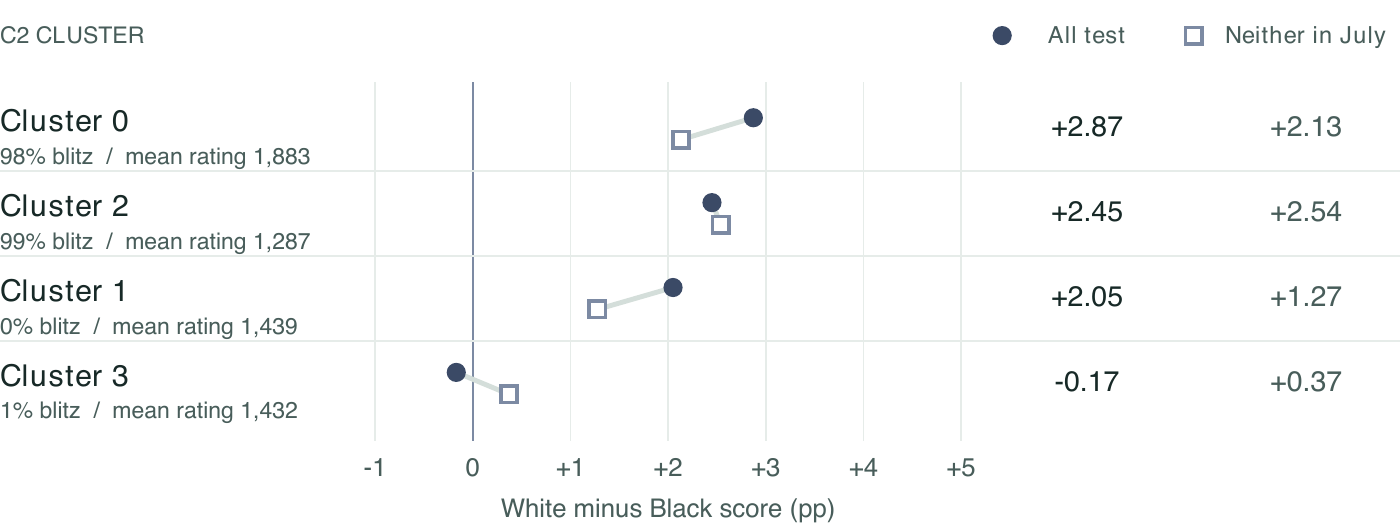

,n_white,n_black,white_minus_black_pp,n_unseen_perspectives,unseen_gap_pp
cluster,,,,,
0,12251,13678,2.87,19263,2.13
1,6073,5929,2.05,9958,1.27
2,10750,9474,2.45,15872,2.54
3,1479,1472,-0.17,2429,0.37


In [2]:
show_figure(paired_dot_figure(cluster_rows, "cluster"),
            "September contrasts by cluster, full and neither-player-in-July cohorts. "
            "Clusters 0, 1 and 2 stay positive; cluster 3 changes from −0.17 to +0.37 pp.")

cluster_summary = pd.read_csv(tables / "C2_cluster_profile_by_color_test.csv").set_index("cluster")
support = pd.DataFrame(clusters).astype({"cluster": int, "n_unseen": int}).set_index("cluster")
cluster_table = cluster_summary[["n_white", "n_black", "white_minus_black_pp"]].assign(
    n_unseen_perspectives=support.n_unseen,
    unseen_gap_pp=support.unseen_gap_pp.astype(float),
)
assert cluster_table.n_white.sum() == cluster_table.n_black.sum() == n_test
assert cluster_table.n_unseen_perspectives.sum() == 2 * n_unseen
display(cluster_table.astype({"n_white": int, "n_black": int}).round(2))

## 2. Compare the model and the manual rule

Both groupings cover the same 61,106 September perspectives, use the same KPI
and meet the 50-per-color display threshold throughout. Groups are assigned to
focal perspectives, so White and Black may contain different games. The peak
gap is +4.62 pp in 2000+ Blitz (White 55.55%, n = 3,297; Black 50.93%,
n = 3,288). The maximum among the four C2 groups is +2.87 pp.

Show the typical magnitude alongside the peak. The support-weighted mean
absolute gap weights each contrast by its White plus Black perspective count
and divides by total perspectives. This gives higher-volume groups more weight.
Four cluster contrasts and eight speed-by-rating contrasts summarize the cohort
at different resolutions. Both statistics describe the chosen grouping and
this window. Neither controls for the composition of the groups.

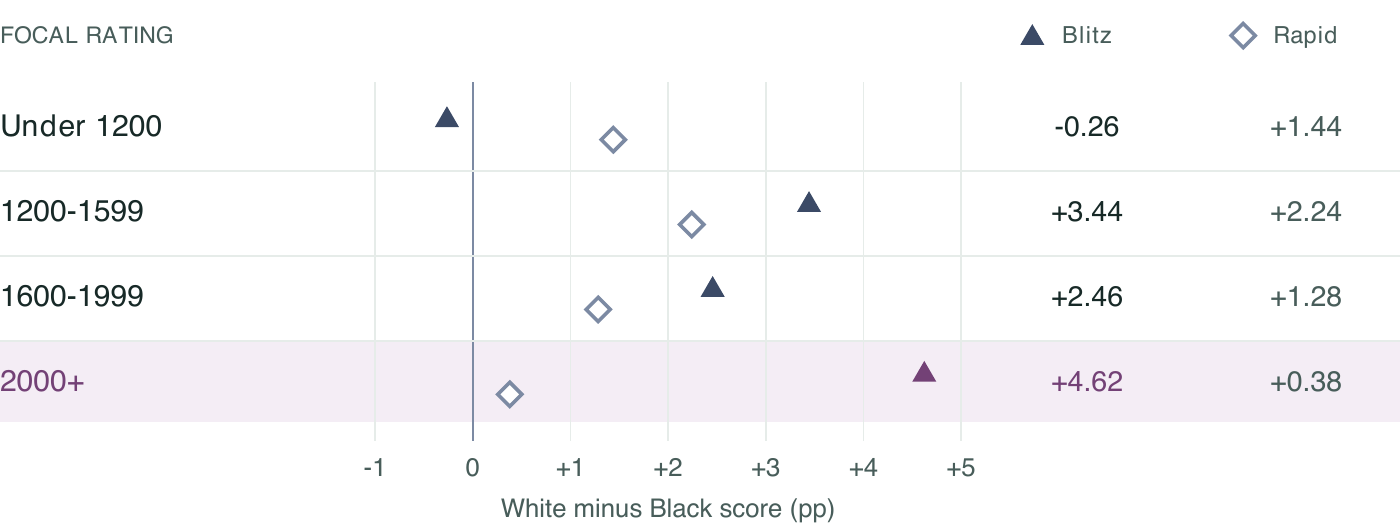

,,n_white,n_black,white_score_pct,black_score_pct,white_minus_black_pp
speed,rating_band,,,,,
blitz,Under 1200,3253,3288,47.99,48.25,-0.26
rapid,Under 1200,1992,2005,48.77,47.33,1.44
blitz,1200-1599,7167,7118,50.93,47.49,3.44
rapid,1200-1599,2930,2872,51.06,48.82,2.24
blitz,1600-1999,9029,9052,51.35,48.89,2.46
rapid,1600-1999,2416,2445,51.32,50.04,1.28
blitz,2000+,3297,3288,55.55,50.93,4.62
rapid,2000+,469,485,55.22,54.85,0.38


,Contrasts,Total perspectives,Smallest color cell,Maximum absolute gap (pp),Support-weighted absolute gap (pp)
Grouping,,,,,
K-prototypes,4,61106,1472,2.87,2.44
Speed × focal rating,8,61106,469,4.62,2.47


In [3]:
show_figure(paired_dot_figure(segment_rows, "segment"),
            "September contrasts by speed and focal rating. Blitz 2000+ has the "
            "largest absolute observed contrast, +4.62 pp.")

segment_table = pd.DataFrame(segments).astype({
    "n_white": int, "n_black": int, "white_score_rate": float,
    "black_score_rate": float, "white_minus_black_pp": float,
}).set_index(["speed", "rating_band"])
assert segment_table.n_white.sum() == segment_table.n_black.sum() == n_test
for name in ("white", "black"):
    segment_table[f"{name}_score_pct"] = 100 * segment_table[f"{name}_score_rate"]
display(segment_table[["n_white", "n_black", "white_score_pct", "black_score_pct",
                       "white_minus_black_pp"]].round(2))

comparisons = []
for name, frame in [("K-prototypes", cluster_table), ("Speed × focal rating", segment_table)]:
    assert frame[["n_white", "n_black"]].min().min() >= 50
    weight = frame.n_white + frame.n_black
    gaps = frame.white_minus_black_pp.abs()
    comparisons.append({
        "Grouping": name, "Contrasts": len(frame), "Total perspectives": int(weight.sum()),
        "Smallest color cell": int(frame[["n_white", "n_black"]].min().min()),
        "Maximum absolute gap (pp)": gaps.max(),
        "Support-weighted absolute gap (pp)": (gaps * weight).sum() / weight.sum(),
    })
display(pd.DataFrame(comparisons).set_index("Grouping").round(2))

## 3. Choose material from September White 2000+ Blitz

Count each game once for White. Choose the five most-played families and order
them by losses. `Other` consists of 106 families. W3's draft drew that aggregate
as a sixth bar. The final moves it into a note so the bars compare named,
reviewable families. The final and draft use the same counts for named families,
with different visual coverage of the aggregate. The table preserves the full
six-row breakdown, including wins, draws and losses for `Other`.

Sicilian Defense has the most losses among the five displayed families. The
preparation script also checks it against every individual family in this
cohort. Its **255 losses in 556 games (45.9%)** provide practical review
volume. The overall cell has 1,370 losses in 3,297 games (41.6%).

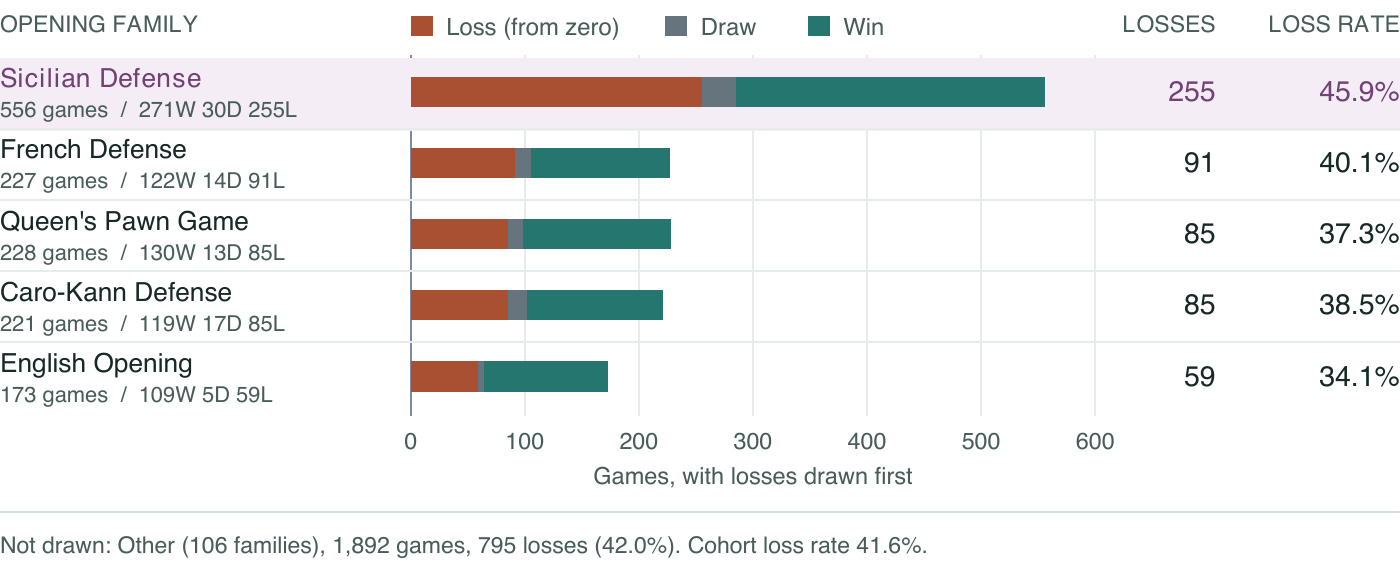

,families,games,win,draw,loss,loss_rate_pct
opening_family,,,,,,
Sicilian Defense,1,556,271,30,255,45.9
French Defense,1,227,122,14,91,40.1
Queen's Pawn Game,1,228,130,13,85,37.3
Caro-Kann Defense,1,221,119,17,85,38.5
English Opening,1,173,109,5,59,34.1
Other (106 families),106,1892,985,112,795,42.0
Total,111,3297,1736,191,1370,41.6


In [4]:
ranked = sorted(breakdown[:-1], key=lambda row: (-row["loss"], -row["games"]))
other = breakdown[-1]
opening_table = pd.DataFrame([*ranked, other]).set_index("opening_family")
totals = opening_table.sum()
selected = segment_table.loc[("blitz", "2000+")]
assert totals.games == selected.n_white
assert abs((totals.win + 0.5 * totals.draw) / totals.games - selected.white_score_rate) < 1e-12
opening_table.loc["Total"] = totals
opening_table["loss_rate_pct"] = 100 * opening_table.loss / opening_table.games
show_figure(ranked_loss_bars(ranked, other, totals.loss / totals.games),
            "Top five White 2000+ Blitz opening families by exposure, ranked by losses. "
            "Sicilian Defense leads with 255 losses in 556 games.")
display(opening_table[["families", "games", "win", "draw", "loss", "loss_rate_pct"]].round(1))

## What to take to the session

Bring representative White losses from Sicilian Defense in 2000+ Blitz and
inspect the positions with the group. The count indicates the volume of
material available. Opponent mix, play choices, repeated players and short
source windows limit conclusions about why games were lost. These results
do not estimate the effect of studying an opening.

The next check would repeat the comparison on untouched dates and include a
sensitivity where both players share a rating band. Establishing a training
improvement would require a separate follow-up with the club.

[Presentation and reading order](../../README.md) ·
[Decisions and feedback](../DECISION_LOG.md) · [Team and AI use](../TEAM_REVIEW.md)